# 03 - Shoreline Extraction (shared water-land boundary)

Corrected extraction: shoreline = shared boundary between classified water and classified land only.


In [26]:
import sys
from pathlib import Path

cwd = Path.cwd()
if (cwd / "notebooks").exists():
    project_root = cwd
elif (cwd.parent / "notebooks").exists():
    project_root = cwd.parent
else:
    project_root = cwd
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

PROJECT_ROOT = project_root
CONFIG_DIR = PROJECT_ROOT / "config"
DATA_DIR = PROJECT_ROOT / "data"
INTERIM_DIR = DATA_DIR / "interim"
PROCESSED_DIR = DATA_DIR / "processed"
TEST_DIR = INTERIM_DIR / "mombasa_test"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
for d in (PROCESSED_DIR / "mombasa_test" / "2024", FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import shapes
import rioxarray as rxr
import matplotlib.pyplot as plt
from shapely.geometry import shape, LineString, MultiLineString
from shapely.ops import unary_union

## Load and validate source classification

Read the water mask with masked reading, exclude nonfinite pixels, and confirm valid values are only 0 and 1. Counts of water, land, and invalid pixels must sum to total pixels.


In [27]:
WATER_MASK_PATH = TEST_DIR / "water_mask" / "water_mask_2024.tif"
with rasterio.open(WATER_MASK_PATH) as src:
    water_mask_da = rxr.open_rasterio(WATER_MASK_PATH, masked=True)
    if "band" in water_mask_da.dims:
        water_mask_da = water_mask_da.isel(band=0)
    print("CRS:", water_mask_da.rio.crs)
    print("Transform:", water_mask_da.rio.transform())
    print("Resolution:", water_mask_da.rio.resolution())
    print("Bounds:", water_mask_da.rio.bounds())
    print("NoData:", water_mask_da.rio.nodata)
    vals = water_mask_da.values
    finite = np.isfinite(vals)
    valid_vals = vals[finite]
    print("Valid unique values:", np.unique(valid_vals))
    if not set(np.unique(valid_vals)).issubset({0, 1}):
        raise ValueError("Invalid classification values present")
    water_pixels = int((valid_vals == 1).sum())
    land_pixels = int((valid_vals == 0).sum())
    invalid_pixels = int((~finite).sum())
    total = water_pixels + land_pixels + invalid_pixels
    print("Water:", water_pixels, "Land:", land_pixels, "Invalid:", invalid_pixels)
    assert total == vals.size
valid_mask = np.isfinite(vals)
water_bool = (vals == 1) & valid_mask
land_bool = (vals == 0) & valid_mask

CRS: EPSG:32737
Transform: | 10.00, 0.00, 572150.00|
| 0.00,-10.00, 9568900.00|
| 0.00, 0.00, 1.00|
Resolution: (10.0, -10.0)
Bounds: (572150.0, 9546770.0, 594370.0, 9568900.0)
NoData: None
Valid unique values: [0. 1.]
Water: 2952072 Land: 1870198 Invalid: 95016


## Vectorize water and land

Vectorize both water and land polygons with 4-connectivity using the original transform. No simplification, smoothing, buffering, or filtering at this stage.


In [28]:
transform = water_mask_da.rio.transform()
water_polys = []
land_polys = []
for geom, val in shapes(
    vals.astype("float32"), mask=water_bool, transform=transform, connectivity=4
):
    if val == 1:
        water_polys.append(shape(geom))
for geom, val in shapes(
    vals.astype("float32"), mask=land_bool, transform=transform, connectivity=4
):
    if val == 0:
        land_polys.append(shape(geom))
water_gdf = gpd.GeoDataFrame(geometry=water_polys, crs=water_mask_da.rio.crs)
land_gdf = gpd.GeoDataFrame(geometry=land_polys, crs=water_mask_da.rio.crs)
print("Water polys:", len(water_gdf), "Land polys:", len(land_gdf))
print(
    "Invalid water geom:",
    (~water_gdf.is_valid).sum(),
    "Invalid land geom:",
    (~land_gdf.is_valid).sum(),
)

Water polys: 1397 Land polys: 394
Invalid water geom: 0 Invalid land geom: 0


## Extract shared water-land boundaries

Dissolve water and land separately, then intersect their boundaries to keep only edges shared by classified water and land.


In [29]:
water_union = unary_union(water_gdf.geometry)
land_union = unary_union(land_gdf.geometry)
shared = water_union.boundary.intersection(land_union.boundary)
lines = []
points = 0


def collect(g):
    global points
    if g.is_empty:
        return
    if isinstance(g, LineString):
        lines.append(g)
    elif isinstance(g, MultiLineString):
        for gg in g.geoms:
            collect(gg)
    elif hasattr(g, "geoms"):
        for gg in g.geoms:
            collect(gg)
    else:
        points += 1


collect(shared)
shared_gdf = gpd.GeoDataFrame(geometry=lines, crs=water_mask_da.rio.crs)
shared_gdf = shared_gdf.drop_duplicates().reset_index(drop=True)
print("Shared lines:", len(shared_gdf), "Point contacts:", points)
if len(shared_gdf) == 0:
    raise RuntimeError("No shared linework found")

Shared lines: 15802 Point contacts: 12


## Spatial checks and provenance

Reproject study area, clip shared linework, load scene metadata, and attach provenance columns.


In [30]:
study_area = gpd.read_file(CONFIG_DIR / "study_area.geojson")
if study_area.crs is None:
    raise ValueError("Study area CRS missing")
study_area = study_area.to_crs(shared_gdf.crs)
clipped = gpd.clip(shared_gdf, study_area)
clipped = clipped[clipped.geometry.notnull() & clipped.geometry.is_valid].reset_index(
    drop=True
)
print("Clipped features:", len(clipped))
scene_meta = pd.read_csv(TEST_DIR / "selected_scene_metadata.csv")
scene_id = scene_meta.loc[0, "scene_id"]
acq_date = str(scene_meta.loc[0, "datetime"])
clipped["shoreline_id"] = range(1, len(clipped) + 1)
clipped["source_scene"] = scene_id
clipped["acquisition_date"] = acq_date
clipped["method"] = "shared_valid_water_land_boundary"
clipped["water_mask_threshold"] = 0.0
clipped["min_water_polygon_area_m2"] = None
clipped["qa_status"] = "candidate_pending_visual_review"
shared_clipped = clipped

Clipped features: 15802


## Export unsimplified candidates

Save all shared-boundary candidates to a separate GeoPackage without removing short lines or inland water.


In [31]:
out_path = (
    PROCESSED_DIR / "mombasa_test" / "2024" / "shoreline_2024_shared_boundary_test.gpkg"
)
shared_clipped.to_file(out_path, driver="GPKG", layer="shoreline_candidates")
total_km = float(shared_clipped.geometry.length.sum()) / 1000.0
print("Features:", len(shared_clipped), "Total km:", round(total_km, 4))
print("Saved:", out_path)

Features: 15802 Total km: 265.95
Saved: [redacted env]\Documents\Data Science Projects\Shoremonitor\data\processed\mombasa_test\2024\shoreline_2024_shared_bounda
ry_test.gpkg


## Diagnostic map

Compare previous shoreline and corrected candidates over the water mask.


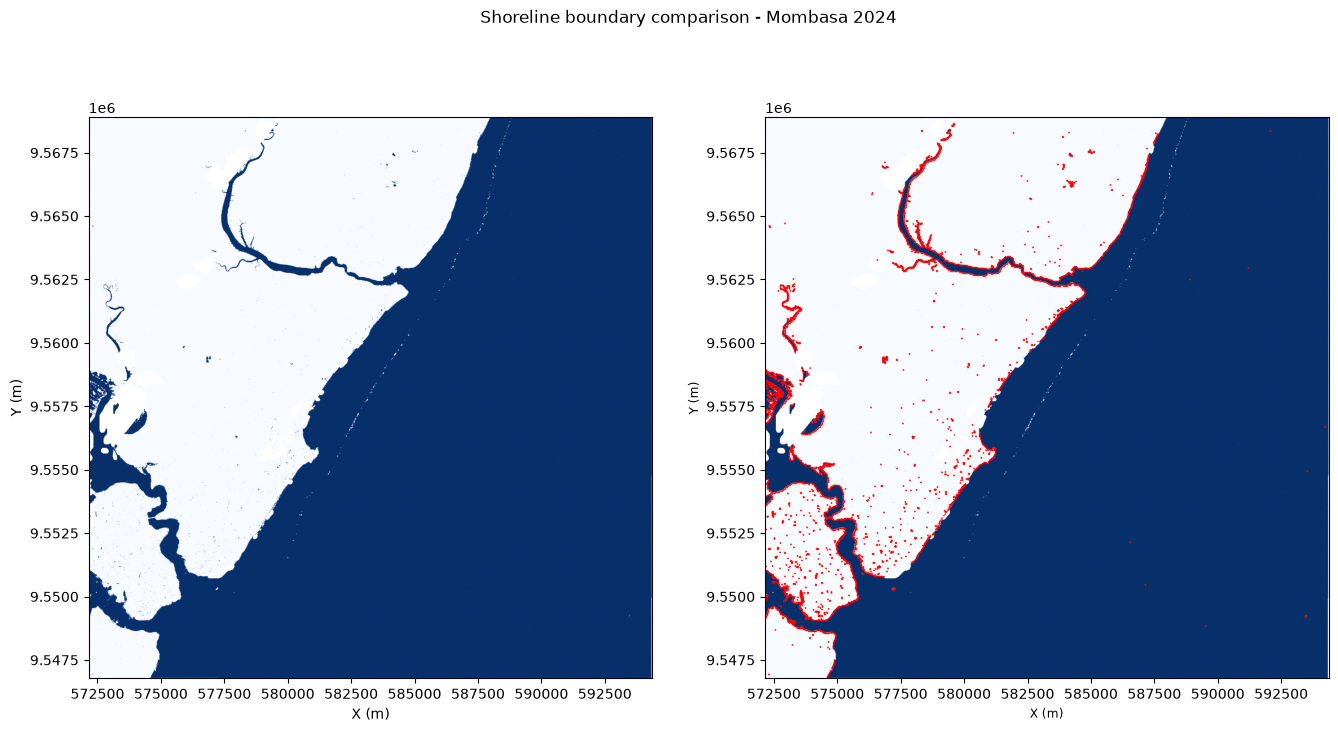

Saved: [redacted env]\Documents\Data Science Projects\Shoremonitor\outputs\figures\mombasa_test_shoreline_boundary_comparison_20
24.png


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
extent = [
    water_mask_da.rio.bounds()[0],
    water_mask_da.rio.bounds()[2],
    water_mask_da.rio.bounds()[1],
    water_mask_da.rio.bounds()[3],
]
axes[0].imshow(water_mask_da.values, cmap="Blues", extent=extent)
axes[1].imshow(water_mask_da.values, cmap="Blues", extent=extent)
shared_clipped.plot(ax=axes[1], color="red", linewidth=1)
for ax in axes:
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
fig.suptitle("Shoreline boundary comparison - Mombasa 2024")
fig_path = FIGURES_DIR / "mombasa_test_shoreline_boundary_comparison_2024.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", fig_path)

## Checks and summary

Verify geometries and save a corrected summary CSV. Document intentional gaps near invalid pixels.


In [34]:
assert shared_clipped.geometry.notnull().all()
assert shared_clipped.geometry.is_valid.all()
summary = pd.DataFrame(
    [
        {
            "scene_id": scene_id,
            "acquisition_date": acq_date,
            "method": "shared_valid_water_land_boundary",
            "crs": str(shared_clipped.crs),
            "candidate_feature_count": len(shared_clipped),
            "candidate_length_km": total_km,
            "water_pixels": water_pixels,
            "land_pixels": land_pixels,
            "invalid_pixels": invalid_pixels,
            "qa_status": "candidate_pending_visual_review",
        }
    ]
)
summary_path = (
    PROCESSED_DIR
    / "mombasa_test"
    / "2024"
    / "shoreline_extraction_summary_corrected_2024.csv"
)
summary.to_csv(summary_path, index=False)
print(summary.to_string(index=False))
print("Saved:", summary_path)

                                              scene_id                 acquisition_date                           method




                                                                                  crs  candidate_feature_count  candidate_length
_km  water_pixels  land_pixels  invalid_pixels                       qa_status
S2A_MSIL2A_20240529T074541_R049_T37MER_20240529T123614 2024-05-29 07:45:41.024000+00:00 shared_valid_water_land_boundary PROJCS[
"WGS 84 / UTM zone 37S",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHO
RITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],A
UTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",39],PA
RAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["
EPSG","9001"]],AXIS["E